In [1]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader, WeightedRandomSampler
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from torch.utils.data import Dataset

from PIL import Image


In [2]:
# Check GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)


Using device: cuda


In [3]:
# Set seed for reproducibility
torch.manual_seed(42)
np.random.seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)


In [4]:
# Image parameters
img_size = 224
batch_size = 32
num_classes = 2
num_epochs = 50
patience = 8


In [5]:
# Data augmentation and normalization
train_transforms = transforms.Compose([
    transforms.RandomResizedCrop(img_size),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.05),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

val_test_transforms = transforms.Compose([
    transforms.Resize((img_size, img_size)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])


In [6]:
# Combined manifest-based dataset
from pathlib import Path

OUT_ROOT = Path('combined_isic_binary')
train_csv = OUT_ROOT / 'train.csv'
val_csv = OUT_ROOT / 'val.csv'
test_csv = OUT_ROOT / 'test.csv'

train_df = pd.read_csv(train_csv)
val_df = pd.read_csv(val_csv)
test_df = pd.read_csv(test_csv)

class_names = ['benign', 'malignant']
class_to_idx = {c:i for i,c in enumerate(class_names)}

class ManifestDataset(Dataset):
    def __init__(self, df, root: Path, transform=None):
        self.df = df.reset_index(drop=True)
        self.root = Path(root)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img_path = self.root / row['filepath']
        img = Image.open(img_path).convert('RGB')
        if self.transform:
            img = self.transform(img)
        label = int(row['label'])
        return img, label

train_data = ManifestDataset(train_df, OUT_ROOT, transform=train_transforms)
val_data = ManifestDataset(val_df, OUT_ROOT, transform=val_test_transforms)
test_data = ManifestDataset(test_df, OUT_ROOT, transform=val_test_transforms)

print('Train/Val/Test:', len(train_data), len(val_data), len(test_data))
print('Train counts:', train_df['label_name'].value_counts())


Train/Val/Test: 7353 1576 1576
Train counts: label_name
benign       4018
malignant    3335
Name: count, dtype: int64


In [7]:
# Dataloaders
train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_data, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_data, batch_size=batch_size, shuffle=False)


In [8]:
# Define model (transfer learning)
model = models.densenet121(weights=models.DenseNet121_Weights.DEFAULT)
for param in model.parameters():
    param.requires_grad = False

in_features = model.classifier.in_features
model.classifier = nn.Sequential(
    nn.Dropout(0.3),
    nn.Linear(in_features, num_classes)
)
model = model.to(device)


In [9]:
# Loss, optimizer, scheduler
train_targets = train_df['label'].values
class_counts = np.bincount(train_targets)
class_weights = 1.0 / class_counts
class_weights_t = torch.tensor(class_weights, dtype=torch.float).to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights_t, label_smoothing=0.02)
optimizer = optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=3)


In [10]:
# Training loop with early stopping (monitor val loss)
best_val_loss = float('inf')
counter = 0
train_acc_hist, val_acc_hist = [], []
train_loss_hist, val_loss_hist = [], []

for epoch in range(num_epochs):
    model.train()
    train_loss, train_correct = 0, 0
    for imgs, labels in train_loader:
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        train_loss += loss.item() * imgs.size(0)
        _, preds = torch.max(outputs, 1)
        train_correct += torch.sum(preds == labels.data)

    train_loss /= len(train_loader.dataset)
    train_acc = train_correct.double() / len(train_loader.dataset)

    model.eval()
    val_loss, val_correct = 0, 0
    with torch.no_grad():
        for imgs, labels in val_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            outputs = model(imgs)
            loss = criterion(outputs, labels)
            val_loss += loss.item() * imgs.size(0)
            _, preds = torch.max(outputs, 1)
            val_correct += torch.sum(preds == labels.data)

    val_loss /= len(val_loader.dataset)
    val_acc = val_correct.double() / len(val_loader.dataset)

    train_acc_hist.append(train_acc.item())
    val_acc_hist.append(val_acc.item())
    train_loss_hist.append(train_loss)
    val_loss_hist.append(val_loss)

    scheduler.step(val_loss)

    print(f"Epoch {epoch+1}/{num_epochs}, "
          f"Train Acc: {train_acc:.4f}, Val Acc: {val_acc:.4f}, "
          f"Val Loss: {val_loss:.4f}")

    # Early stopping
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), 'skin_lesions_model_densenet121.pth')
        counter = 0
    else:
        counter += 1
        if counter >= patience:
            print("Early stopping.")
            break

# Load best model
model.load_state_dict(torch.load('skin_lesions_model_densenet121.pth'))


Epoch 1/50, Train Acc: 0.7442, Val Acc: 0.7855, Val Loss: 0.4605
Epoch 2/50, Train Acc: 0.7665, Val Acc: 0.7792, Val Loss: 0.4559
Epoch 3/50, Train Acc: 0.7736, Val Acc: 0.7849, Val Loss: 0.4589
Epoch 4/50, Train Acc: 0.7820, Val Acc: 0.8204, Val Loss: 0.4197
Epoch 5/50, Train Acc: 0.7772, Val Acc: 0.8014, Val Loss: 0.4368
Epoch 6/50, Train Acc: 0.7786, Val Acc: 0.8211, Val Loss: 0.4201
Epoch 7/50, Train Acc: 0.7753, Val Acc: 0.8185, Val Loss: 0.4160
Epoch 8/50, Train Acc: 0.7639, Val Acc: 0.8369, Val Loss: 0.4079
Epoch 9/50, Train Acc: 0.7742, Val Acc: 0.8268, Val Loss: 0.4275
Epoch 10/50, Train Acc: 0.7776, Val Acc: 0.8204, Val Loss: 0.4130
Epoch 11/50, Train Acc: 0.7723, Val Acc: 0.7963, Val Loss: 0.4343
Epoch 12/50, Train Acc: 0.7760, Val Acc: 0.8306, Val Loss: 0.4132
Epoch 13/50, Train Acc: 0.7814, Val Acc: 0.8001, Val Loss: 0.4344
Epoch 14/50, Train Acc: 0.7808, Val Acc: 0.8039, Val Loss: 0.4291
Epoch 15/50, Train Acc: 0.7831, Val Acc: 0.7931, Val Loss: 0.4395
Epoch 16/50, Train 

<All keys matched successfully>

In [11]:
# Optional fine-tuning (unfreeze last block for a few more epochs)
for name, param in model.named_parameters():
    if name.startswith('layer4'):
        param.requires_grad = True

fine_tune_epochs = 10
optimizer = optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=1e-4, weight_decay=1e-4)

for epoch in range(fine_tune_epochs):
    model.train()
    train_loss, train_correct = 0, 0
    for imgs, labels in train_loader:
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        train_loss += loss.item() * imgs.size(0)
        _, preds = torch.max(outputs, 1)
        train_correct += torch.sum(preds == labels.data)

    train_loss /= len(train_loader.dataset)
    train_acc = train_correct.double() / len(train_loader.dataset)

    model.eval()
    val_loss, val_correct = 0, 0
    with torch.no_grad():
        for imgs, labels in val_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            outputs = model(imgs)
            loss = criterion(outputs, labels)
            val_loss += loss.item() * imgs.size(0)
            _, preds = torch.max(outputs, 1)
            val_correct += torch.sum(preds == labels.data)

    val_loss /= len(val_loader.dataset)
    val_acc = val_correct.double() / len(val_loader.dataset)

    print(f"Fine-tune Epoch {epoch+1}/{fine_tune_epochs}, "
          f"Train Acc: {train_acc:.4f}, Val Acc: {val_acc:.4f}, "
          f"Val Loss: {val_loss:.4f}")

# Save final fine-tuned model
torch.save(model.state_dict(), 'skin_lesions_model_densenet121.pth')


Fine-tune Epoch 1/10, Train Acc: 0.7814, Val Acc: 0.8249, Val Loss: 0.4090
Fine-tune Epoch 2/10, Train Acc: 0.7872, Val Acc: 0.8141, Val Loss: 0.4181
Fine-tune Epoch 3/10, Train Acc: 0.7908, Val Acc: 0.8077, Val Loss: 0.4235
Fine-tune Epoch 4/10, Train Acc: 0.7964, Val Acc: 0.8147, Val Loss: 0.4207
Fine-tune Epoch 5/10, Train Acc: 0.7880, Val Acc: 0.8052, Val Loss: 0.4264
Fine-tune Epoch 6/10, Train Acc: 0.7882, Val Acc: 0.8166, Val Loss: 0.4167
Fine-tune Epoch 7/10, Train Acc: 0.7899, Val Acc: 0.8255, Val Loss: 0.4130
Fine-tune Epoch 8/10, Train Acc: 0.7937, Val Acc: 0.8173, Val Loss: 0.4187
Fine-tune Epoch 9/10, Train Acc: 0.7865, Val Acc: 0.8185, Val Loss: 0.4175
Fine-tune Epoch 10/10, Train Acc: 0.7793, Val Acc: 0.8198, Val Loss: 0.4154


In [12]:
# Test evaluation
model.eval()
test_correct = 0
with torch.no_grad():
    for imgs, labels in test_loader:
        imgs, labels = imgs.to(device), labels.to(device)
        outputs = model(imgs)
        _, preds = torch.max(outputs, 1)
        test_correct += torch.sum(preds == labels.data)

test_acc = test_correct.double() / len(test_loader.dataset)
print(f"Test Accuracy: {test_acc:.4f}")


Test Accuracy: 0.8154


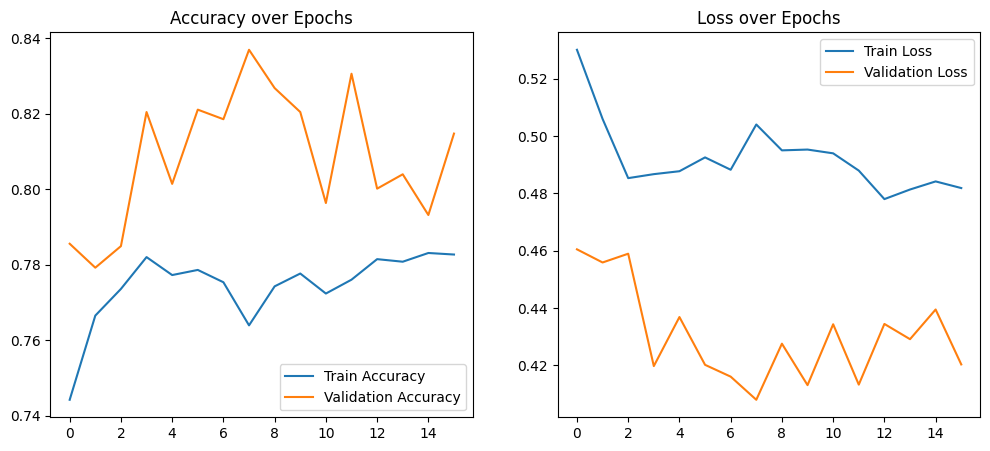

In [13]:
# Plot training history
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(train_acc_hist, label='Train Accuracy')
plt.plot(val_acc_hist, label='Validation Accuracy')
plt.title('Accuracy over Epochs')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(train_loss_hist, label='Train Loss')
plt.plot(val_loss_hist, label='Validation Loss')
plt.title('Loss over Epochs')
plt.legend()
plt.show()


In [14]:
# Load best model for evaluation
model = models.densenet121(weights=None)
in_features = model.classifier.in_features
model.classifier = nn.Sequential(
    nn.Dropout(0.3),
    nn.Linear(in_features, num_classes)
)
model.load_state_dict(torch.load('skin_lesions_model_densenet121.pth'))
model = model.to(device)


In [ ]:
image_path = r"Skin Lesions Classification\test\malignant\3.jpg"
label, confidence = predict_image(image_path, model)
print(f"Prediction: {label} ({confidence*100:.2f}% confidence)")


Prediction: malignant (99.71% confidence)


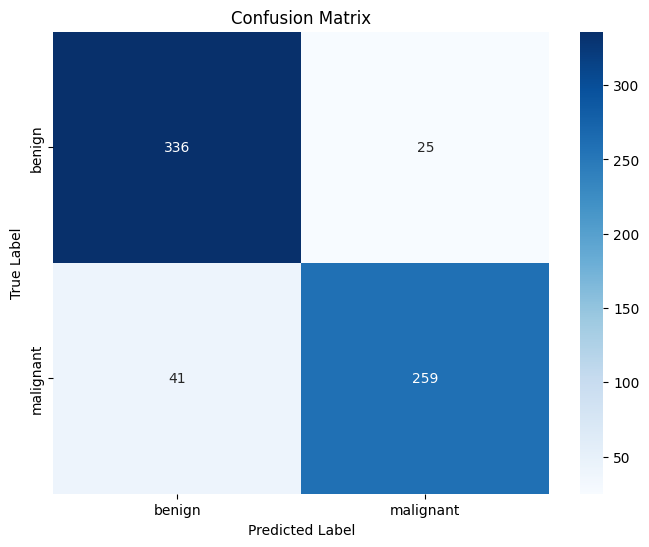

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

# Collect predictions and true labels
all_preds = []
all_labels = []

model.eval()
with torch.no_grad():
    for imgs, labels in test_loader:
        imgs = imgs.to(device)
        outputs = model(imgs)
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

# Confusion matrix
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=class_names, yticklabels=class_names, cmap='Blues')
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()


In [ ]:
print("Classification Report:\n")
print(classification_report(all_labels, all_preds, target_names=class_names))


Classification Report:

              precision    recall  f1-score   support

      benign       0.89      0.93      0.91       361
   malignant       0.91      0.86      0.89       300

    accuracy                           0.90       661
   macro avg       0.90      0.90      0.90       661
weighted avg       0.90      0.90      0.90       661



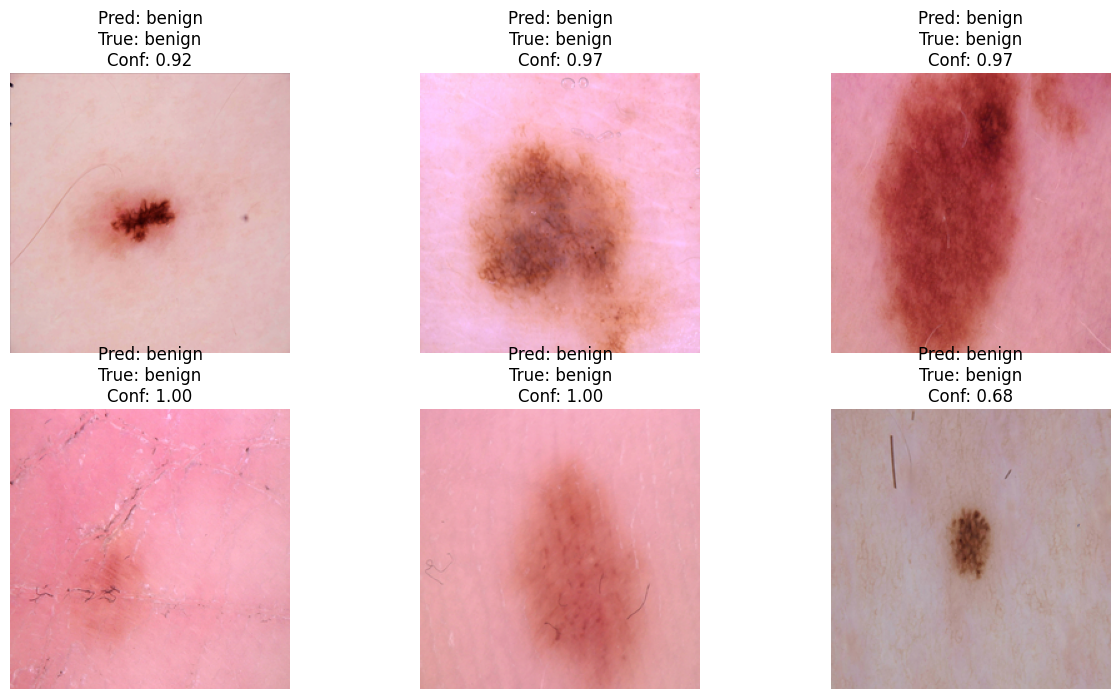

In [ ]:
def visualize_predictions(model, data_loader, num_images=6):
    model.eval()
    images_shown = 0
    plt.figure(figsize=(15, 8))

    with torch.no_grad():
        for imgs, labels in data_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            outputs = model(imgs)
            probs = torch.softmax(outputs, dim=1)
            _, preds = torch.max(probs, 1)

            for i in range(imgs.size(0)):
                if images_shown == num_images:
                    return
                image = imgs[i].cpu().permute(1, 2, 0).numpy()
                image = (image * np.array([0.229, 0.224, 0.225])) + np.array([0.485, 0.456, 0.406])
                image = np.clip(image, 0, 1)
                plt.subplot(2, 3, images_shown+1)
                plt.imshow(image)
                plt.axis('off')
                plt.title(f"Pred: {class_names[preds[i]]}\nTrue: {class_names[labels[i]]}\nConf: {probs[i][preds[i]]:.2f}")
                images_shown += 1

visualize_predictions(model, test_loader)


ROC-AUC: 0.5535
PR-AUC: 0.5023


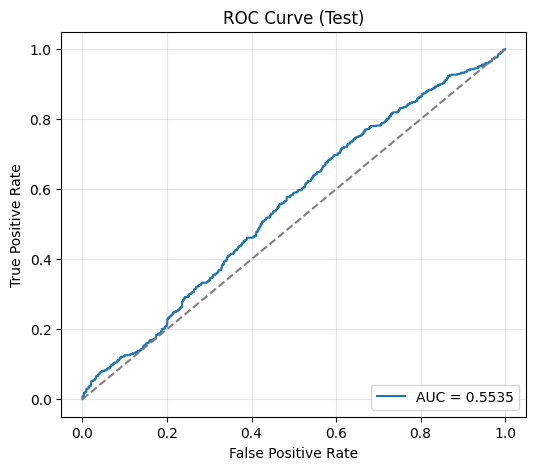

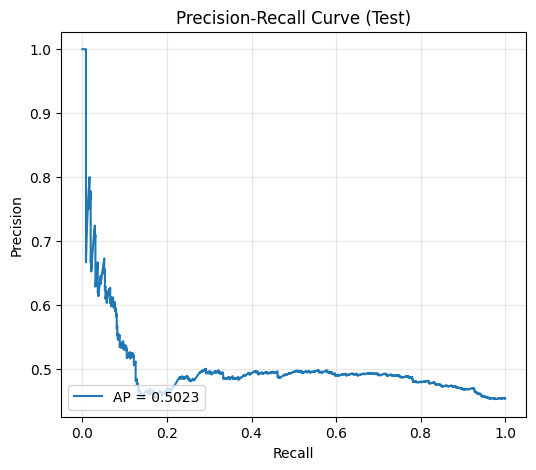

In [10]:
# --- ROC/PR AUC evaluation cell (auto-added) ---
import numpy as np
import torch
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve, auc, precision_recall_curve, average_precision_score

if "device" not in globals():
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

missing = [name for name in ["model", "test_loader"] if name not in globals()]
if missing:
    raise RuntimeError(
        "Missing required objects: " + ", ".join(missing) +
        ". Run the notebook setup/training/loading cells first, then run this AUC cell."
    )

model.eval()
y_true, y_prob_pos = [], []

with torch.no_grad():
    for imgs, labels in test_loader:
        imgs = imgs.to(device)
        labels = labels.to(device)
        logits = model(imgs)
        probs = torch.softmax(logits, dim=1)

        y_true.extend(labels.cpu().numpy().tolist())
        y_prob_pos.extend(probs[:, 1].cpu().numpy().tolist())

y_true = np.array(y_true)
y_prob_pos = np.array(y_prob_pos)

roc_auc = roc_auc_score(y_true, y_prob_pos)
pr_auc = average_precision_score(y_true, y_prob_pos)

print(f"ROC-AUC: {roc_auc:.4f}")
print(f"PR-AUC: {pr_auc:.4f}")

fpr, tpr, _ = roc_curve(y_true, y_prob_pos)
roc_curve_auc = auc(fpr, tpr)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"AUC = {roc_curve_auc:.4f}")
plt.plot([0, 1], [0, 1], "--", color="gray")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve (Test)")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

precision, recall, _ = precision_recall_curve(y_true, y_prob_pos)

plt.figure(figsize=(6, 5))
plt.plot(recall, precision, label=f"AP = {pr_auc:.4f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve (Test)")
plt.legend(loc="lower left")
plt.grid(alpha=0.3)
plt.show()
